# Canadian Industry Strength Score (CISS): September 2026 Snapshot

This notebook compares recent employment growth, growth consistency, and five-year employment changes across 17 Canadian industry categories using Statistics Canada Table 14-10-0355-01.

CISS is a custom ranking for this project, not an official Statistics Canada indicator. The results in the accompanying README use the data retrieved on October 23, 2026, through September 2026. Re-running this notebook downloads the current table, so results may change after new releases or revisions.

## 1. Import libraries

In [1]:
# Import the libraries I need for this project

import io
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.3.5


## 2. Download the Statistics Canada data

In [2]:
# Download the data if the CSV file is not already available

url = "https://www150.statcan.gc.ca/n1/tbl/csv/14100355-eng.zip"
data_folder = Path("statcan_employment_data")
file_path = data_folder / "14100355.csv"

data_folder.mkdir(parents=True, exist_ok=True)

if not file_path.exists():
    response = requests.get(url, timeout=180)
    response.raise_for_status()

    print("ZIP file size:", round(len(response.content) / (1024 ** 2), 2), "MB")

    with zipfile.ZipFile(io.BytesIO(response.content)) as z:
        print("Files in ZIP:", z.namelist())
        z.extractall(data_folder)
else:
    print("Using the CSV file already in:", file_path)

print("Data file is ready!")

Using the CSV file already in: statcan_employment_data/14100355.csv
Data file is ready!


## 3. Load the data

In [3]:
# Load the Statistics Canada CSV file

df = pd.read_csv(file_path, low_memory=False)

print("Dataset shape:", df.shape)
print("Latest month in the source data:", df["REF_DATE"].max())
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (690312, 17)
Latest month in the source data: 2026-09

Column names:
['REF_DATE', 'GEO', 'DGUID', 'North American Industry Classification System (NAICS)', 'Statistics', 'Data type', 'UOM', 'UOM_ID', 'SCALAR_FACTOR', 'SCALAR_ID', 'VECTOR', 'COORDINATE', 'VALUE', 'STATUS', 'SYMBOL', 'TERMINATED', 'DECIMALS']


,REF_DATE,GEO,DGUID,North American Industry Classification System (NAICS),Statistics,Data type,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
0,1976-01,Canada,2021A000011124,"Total employed, all industries",Estimate,Seasonally adjusted,Persons in thousands,428,thousands,3,v2057603,1.1.1.1,9636.7,NaN,NaN,NaN,1
1,1976-01,Canada,2021A000011124,"Total employed, all industries",Estimate,Trend-cycle,Persons in thousands,428,thousands,3,v123355106,1.1.1.3,9667.7,NaN,NaN,NaN,1
2,1976-01,Canada,2021A000011124,"Total employed, all industries",Estimate,Unadjusted,Persons in thousands,428,thousands,3,v2057812,1.1.1.2,9271.4,NaN,NaN,NaN,1
3,1976-01,Canada,2021A000011124,"Total employed, all industries",Standard error of estimate,Seasonally adjusted,Persons in thousands,428,thousands,3,v101893652,1.1.2.1,NaN,..,NaN,NaN,1
4,1976-01,Canada,2021A000011124,"Total employed, all industries",Standard error of month-to-month change,Seasonally adjusted,Persons in thousands,428,thousands,3,v101893653,1.1.3.1,NaN,..,NaN,NaN,1


## 4. Clean the data

In [4]:
# Keep Canada-level seasonally adjusted employment estimates

canada = df[
    (df["GEO"] == "Canada") &
    (df["Statistics"] == "Estimate") &
    (df["Data type"] == "Seasonally adjusted")
][
    [
        "REF_DATE",
        "North American Industry Classification System (NAICS)",
        "VALUE"
    ]
].copy()

# Rename the columns to make them easier to use
canada = canada.rename(columns={
    "REF_DATE": "date",
    "North American Industry Classification System (NAICS)": "industry",
    "VALUE": "employment_thousands"
})

# Convert dates and employment values
canada["date"] = pd.to_datetime(canada["date"])
canada["employment_thousands"] = pd.to_numeric(
    canada["employment_thousands"], errors="coerce"
)

print("Clean dataset shape:", canada.shape)
print("Date range:", canada["date"].min(), "to", canada["date"].max())
print("Number of industries before exclusions:", canada["industry"].nunique())
display(canada.head())

Clean dataset shape: (12525, 3)
Date range: 1976-01-01 00:00:00 to 2026-09-01 00:00:00
Number of industries before exclusions: 21


,date,industry,employment_thousands
0,1976-01-01,"Total employed, all industries",9636.7
6,1976-01-01,Goods-producing sector,3312.5
12,1976-01-01,"Agriculture [111-112, 1100, 1151-1152]",463.6
18,1976-01-01,"Forestry, fishing, mining, quarrying, oil and ...",244.2
24,1976-01-01,Utilities [22],110.4


## 5. Check data quality

In [5]:
# Check missing values and duplicate industry-month records

print("Missing values:")
print(canada.isna().sum())

duplicates = canada.duplicated(["date", "industry"]).sum()
print("\nDuplicate industry-month rows:", duplicates)

# Check how many months are available for each industry
coverage = (
    canada.groupby("industry")
    .agg(
        months=("date", "count"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
    .sort_values("months")
)
display(coverage)

assert canada.isna().sum().sum() == 0
assert duplicates == 0

Missing values:
date                    0
industry                0
employment_thousands    0
dtype: int64

Duplicate industry-month rows: 0


,months,first_date,last_date
industry,,,
Retail trade [44-45],477,1987-01-01,2026-09-01
Wholesale trade [41],477,1987-01-01,2026-09-01
"Business, building and other support services [55-56]",609,1976-01-01,2026-09-01
Accommodation and food services [72],609,1976-01-01,2026-09-01
Educational services [61],609,1976-01-01,2026-09-01
"Finance, insurance, real estate, rental and leasing [52-53]",609,1976-01-01,2026-09-01
"Forestry, fishing, mining, quarrying, oil and gas [21, 113-114, 1153, 2100]",609,1976-01-01,2026-09-01
"Agriculture [111-112, 1100, 1151-1152]",609,1976-01-01,2026-09-01
Goods-producing sector,609,1976-01-01,2026-09-01


## 6. Select the 17 industries and calculate year-over-year growth

In [6]:
# Remove broad totals and the overlapping wholesale-and-retail category

exclude = [
    "Total employed, all industries",
    "Goods-producing sector",
    "Services-producing sector",
    "Wholesale and retail trade [41, 44-45]"
]

industries = canada[~canada["industry"].isin(exclude)].copy()
industries = industries.sort_values(["industry", "date"]).reset_index(drop=True)

print("Number of industries:", industries["industry"].nunique())

# Check that each industry has consecutive monthly data
months_are_consecutive = industries.groupby("industry")["date"].apply(
    lambda dates: dates.diff().dropna().dt.days.between(28, 31).all()
)
assert months_are_consecutive.all(), "Some months are missing from an industry series."

# Compare each month with the same month one year earlier
industries["employment_previous_year"] = (
    industries.groupby("industry")["employment_thousands"].shift(12)
)
industries["yoy_growth_pct"] = (
    industries["employment_thousands"] / industries["employment_previous_year"] - 1
) * 100

latest_date = industries["date"].max()
print("Latest month:", latest_date.strftime("%B %Y"))

latest_industries = industries[industries["date"] == latest_date].sort_values(
    "yoy_growth_pct", ascending=False
)
display(
    latest_industries[
        ["industry", "employment_thousands", "employment_previous_year", "yoy_growth_pct"]
    ].round(2)
)

Number of industries: 17


Latest month: September 2026


,industry,employment_thousands,employment_previous_year,yoy_growth_pct
5480,"Information, culture and recreation [51, 71]",879.1,835.8,5.18
9002,Transportation and warehousing [48-49],1119.2,1066.4,4.95
6698,Other services (except public administration) ...,814.0,781.8,4.12
4871,Health care and social assistance [62],2992.8,2899.8,3.21
1826,"Business, building and other support services ...",693.4,674.3,2.83
7307,"Professional, scientific and technical service...",2037.4,2007.6,1.48
2435,Construction [23],1646.8,1626.8,1.23
608,Accommodation and food services [72],1194.9,1184.4,0.89
8393,Retail trade [44-45],2234.5,2239.3,-0.21
6089,Manufacturing [31-33],1834.3,1847.2,-0.70


## 7. Measure growth consistency

In [7]:
# Check the share of the last 12 months with positive year-over-year growth

window_start = latest_date - pd.DateOffset(months=11)
recent = industries[
    (industries["date"] >= window_start) &
    (industries["date"] <= latest_date)
].copy()

consistency = (
    recent.groupby("industry")
    .agg(
        positive_months=("yoy_growth_pct", lambda values: (values > 0).sum()),
        months_checked=("yoy_growth_pct", "count")
    )
    .reset_index()
)

assert (consistency["months_checked"] == 12).all()
consistency["positive_growth_pct"] = (
    consistency["positive_months"] / consistency["months_checked"] * 100
)

consistency = consistency.sort_values(
    "positive_growth_pct", ascending=False
).reset_index(drop=True)
display(consistency.round(2))

,industry,positive_months,months_checked,positive_growth_pct
0,Health care and social assistance [62],12,12,100.00
1,"Information, culture and recreation [51, 71]",12,12,100.00
2,Transportation and warehousing [48-49],11,12,91.67
3,Other services (except public administration) ...,11,12,91.67
4,Accommodation and food services [72],10,12,83.33
5,"Agriculture [111-112, 1100, 1151-1152]",10,12,83.33
6,Utilities [22],10,12,83.33
7,"Forestry, fishing, mining, quarrying, oil and ...",9,12,75.00
8,Public administration [91],8,12,66.67
9,Wholesale trade [41],7,12,58.33


## 8. Calculate the Canadian Industry Strength Score (CISS)

In [8]:
# Get the latest growth estimate for each industry

latest = (
    industries[industries["date"] == latest_date]
    [["industry", "employment_previous_year", "yoy_growth_pct"]]
    .rename(columns={"yoy_growth_pct": "latest_growth"})
)

# Get Statistics Canada's standard error of year-over-year change
industry_column = "North American Industry Classification System (NAICS)"
se = df[
    (df["GEO"] == "Canada") &
    (df["Statistics"] == "Standard error of year-over-year change") &
    (df["Data type"] == "Seasonally adjusted") &
    (df["REF_DATE"] == latest_date.strftime("%Y-%m"))
][[industry_column, "VALUE"]].rename(columns={
    industry_column: "industry",
    "VALUE": "se_yoy_thousands"
})
se["se_yoy_thousands"] = pd.to_numeric(se["se_yoy_thousands"], errors="coerce")

# Combine latest growth, consistency, and standard-error data
ciss_17 = (
    latest
    .merge(
        consistency[["industry", "positive_growth_pct"]],
        on="industry",
        validate="one_to_one"
    )
    .merge(se, on="industry", how="left", validate="one_to_one")
)

assert len(ciss_17) == 17
assert ciss_17["se_yoy_thousands"].notna().all()

# Approximate the standard error in percentage points
ciss_17["se_yoy_pct"] = (
    ciss_17["se_yoy_thousands"] / ciss_17["employment_previous_year"] * 100
)
ciss_17["growth_to_se"] = ciss_17["latest_growth"] / ciss_17["se_yoy_pct"]

# Rank industries on growth and consistency; ties share an average rank
ciss_17["growth_rank"] = ciss_17["latest_growth"].rank(pct=True) * 100
ciss_17["consistency_rank"] = ciss_17["positive_growth_pct"].rank(pct=True) * 100

# Give the two ranks equal weight
ciss_17["CISS"] = (
    0.5 * ciss_17["growth_rank"] +
    0.5 * ciss_17["consistency_rank"]
)

# Use latest growth to break ties for display only; tied CISS scores remain tied
ciss_17 = ciss_17.sort_values(
    ["CISS", "latest_growth"], ascending=[False, False], kind="mergesort"
).reset_index(drop=True)

display(
    ciss_17[[
        "industry", "latest_growth", "se_yoy_pct", "growth_to_se",
        "positive_growth_pct", "growth_rank", "consistency_rank", "CISS"
    ]].round(2)
)

,industry,latest_growth,se_yoy_pct,growth_to_se,positive_growth_pct,growth_rank,consistency_rank,CISS
0,"Information, culture and recreation [51, 71]",5.18,3.09,1.68,100.00,100.00,97.06,98.53
1,Transportation and warehousing [48-49],4.95,2.33,2.13,91.67,94.12,85.29,89.71
2,Health care and social assistance [62],3.21,1.14,2.80,100.00,82.35,97.06,89.71
3,Other services (except public administration) ...,4.12,2.78,1.48,91.67,88.24,85.29,86.76
4,Accommodation and food services [72],0.89,2.38,0.37,83.33,58.82,70.59,64.71
5,"Professional, scientific and technical service...",1.48,1.74,0.85,58.33,70.59,44.12,57.35
6,"Business, building and other support services ...",2.83,3.40,0.83,41.67,76.47,29.41,52.94
7,Public administration [91],-1.51,1.75,-0.86,66.67,41.18,52.94,47.06
8,"Forestry, fishing, mining, quarrying, oil and ...",-2.99,3.99,-0.75,75.00,29.41,58.82,44.12
9,Construction [23],1.23,1.88,0.65,33.33,64.71,20.59,42.65


## 9. Check alternative weights

In [9]:
# Test different weights for growth and consistency

ciss_17["score_50_50"] = (
    0.5 * ciss_17["growth_rank"] + 0.5 * ciss_17["consistency_rank"]
)
ciss_17["score_70_30"] = (
    0.7 * ciss_17["growth_rank"] + 0.3 * ciss_17["consistency_rank"]
)
ciss_17["score_30_70"] = (
    0.3 * ciss_17["growth_rank"] + 0.7 * ciss_17["consistency_rank"]
)

for score in ["score_50_50", "score_70_30", "score_30_70"]:
    print("\nTop four industries:", score)
    display(
        ciss_17.sort_values([score, "latest_growth"], ascending=[False, False])
        [["industry", score]]
        .head(4)
        .round(2)
        .reset_index(drop=True)
    )


Top four industries: score_50_50


,industry,score_50_50
0,"Information, culture and recreation [51, 71]",98.53
1,Transportation and warehousing [48-49],89.71
2,Health care and social assistance [62],89.71
3,Other services (except public administration) ...,86.76



Top four industries: score_70_30


,industry,score_70_30
0,"Information, culture and recreation [51, 71]",99.12
1,Transportation and warehousing [48-49],91.47
2,Other services (except public administration) ...,87.35
3,Health care and social assistance [62],86.76



Top four industries: score_30_70


,industry,score_30_70
0,"Information, culture and recreation [51, 71]",97.94
1,Health care and social assistance [62],92.65
2,Transportation and warehousing [48-49],87.94
3,Other services (except public administration) ...,86.18


## 10. Compare five-year employment change and export results

In [10]:
# Compare employment between the same month five years apart

five_year_start = latest_date - pd.DateOffset(years=5)

start_vals = industries[industries["date"] == five_year_start][
    ["industry", "employment_thousands"]
].rename(columns={"employment_thousands": "employment_start"})

end_vals = industries[industries["date"] == latest_date][
    ["industry", "employment_thousands"]
].rename(columns={"employment_thousands": "employment_end"})

five_year = start_vals.merge(end_vals, on="industry", validate="one_to_one")
five_year["five_year_change_pct"] = (
    five_year["employment_end"] / five_year["employment_start"] - 1
) * 100

# Build the final table using the updated CISS scores
final_results = (
    ciss_17[[
        "industry", "latest_growth", "se_yoy_pct", "growth_to_se",
        "positive_growth_pct", "CISS"
    ]]
    .merge(
        five_year[["industry", "five_year_change_pct"]],
        on="industry",
        how="left",
        validate="one_to_one"
    )
    .rename(columns={
        "industry": "Industry",
        "latest_growth": "Latest growth (%)",
        "se_yoy_pct": "Std. error of growth (pts)",
        "growth_to_se": "Growth / std. error",
        "positive_growth_pct": "Positive months (%)",
        "CISS": "CISS score",
        "five_year_change_pct": "5-year employment change (%)"
    })
    .sort_values(["CISS score", "Latest growth (%)"], ascending=[False, False], kind="mergesort")
    .reset_index(drop=True)
)

assert len(final_results) == 17
assert final_results["5-year employment change (%)"].notna().all()

print("Number of industries:", len(final_results))
print("Missing five-year changes:", final_results["5-year employment change (%)"].isna().sum())
display(final_results.round(2))

# Save with proper CSV quoting, including industry names that contain commas
output_file = Path("canadian_industry_strength_results.csv")
final_results.round(2).to_csv(output_file, index=False)
print("Saved results to:", output_file)

Number of industries: 17
Missing five-year changes: 0


,Industry,Latest growth (%),Std. error of growth (pts),Growth / std. error,Positive months (%),CISS score,5-year employment change (%)
0,"Information, culture and recreation [51, 71]",5.18,3.09,1.68,100.00,98.53,17.26
1,Transportation and warehousing [48-49],4.95,2.33,2.13,91.67,89.71,13.23
2,Health care and social assistance [62],3.21,1.14,2.80,100.00,89.71,17.76
3,Other services (except public administration) ...,4.12,2.78,1.48,91.67,86.76,14.94
4,Accommodation and food services [72],0.89,2.38,0.37,83.33,64.71,14.45
5,"Professional, scientific and technical service...",1.48,1.74,0.85,58.33,57.35,18.49
6,"Business, building and other support services ...",2.83,3.40,0.83,41.67,52.94,0.71
7,Public administration [91],-1.51,1.75,-0.86,66.67,47.06,8.96
8,"Forestry, fishing, mining, quarrying, oil and ...",-2.99,3.99,-0.75,75.00,44.12,-1.21
9,Construction [23],1.23,1.88,0.65,33.33,42.65,12.10


Saved results to: canadian_industry_strength_results.csv


## 11. Plot CISS scores

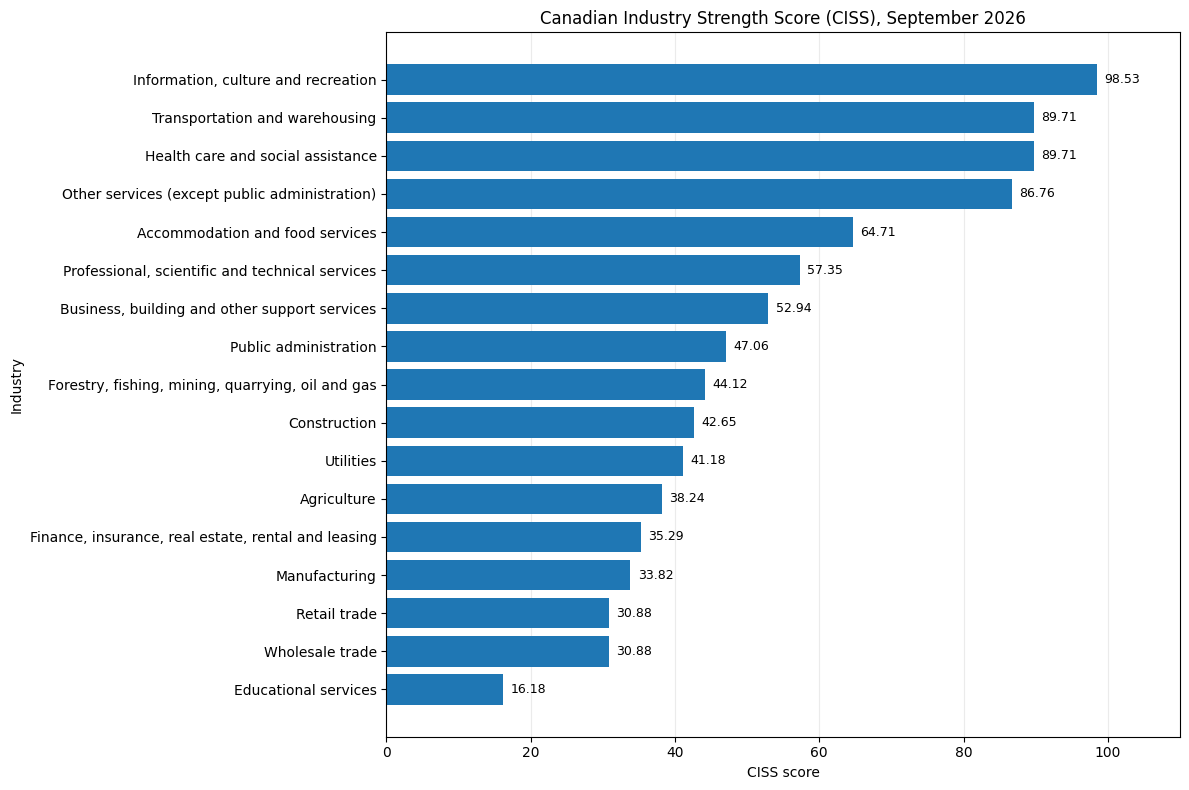

In [11]:
# Create a bar chart of CISS scores

chart = final_results.copy()
chart["label"] = chart["Industry"].str.replace(r"\s*\[.*?\]", "", regex=True)
chart = chart.sort_values("CISS score", ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(chart["label"], chart["CISS score"])

for bar in bars:
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}",
        va="center",
        fontsize=9
    )

ax.set_title(f"Canadian Industry Strength Score (CISS), {latest_date:%B %Y}")
ax.set_xlabel("CISS score")
ax.set_ylabel("Industry")
ax.set_xlim(0, 110)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()

figures_folder = Path("figures")
figures_folder.mkdir(exist_ok=True)
fig.savefig(figures_folder / "ciss_ranking.png", dpi=160, bbox_inches="tight")
plt.show()

## 12. Plot recent growth and consistency

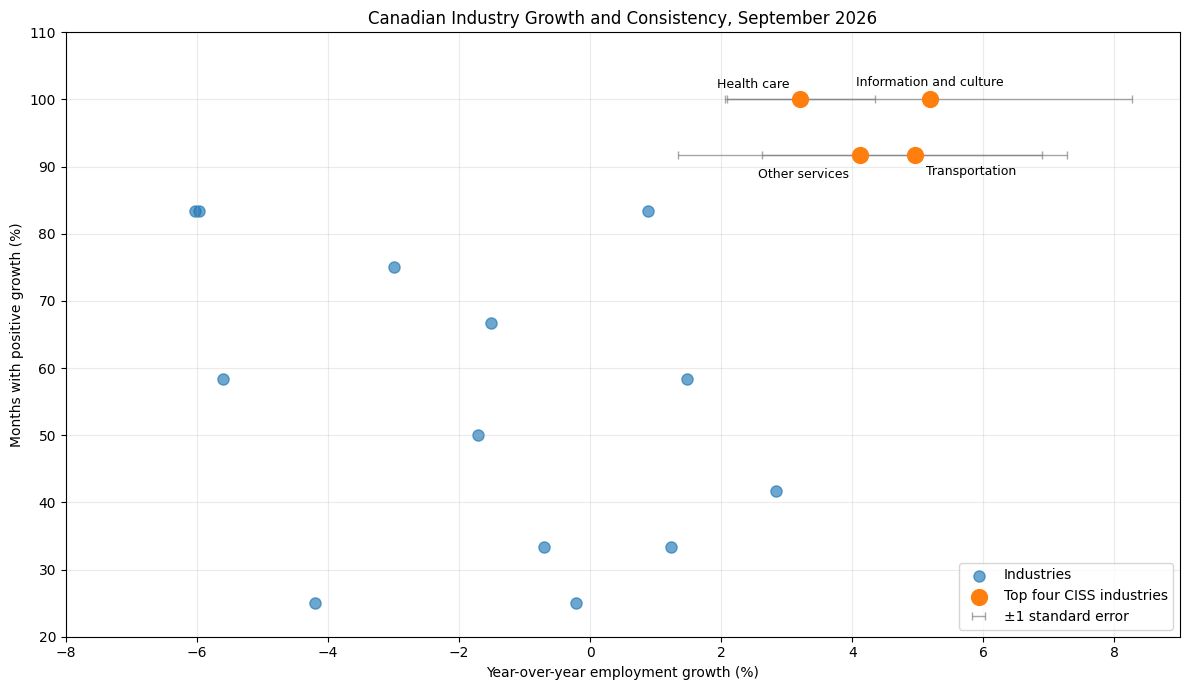

In [12]:
# Compare latest employment growth with growth consistency

top4 = ciss_17.nlargest(4, "CISS")
short_names = {
    "Information, culture and recreation [51, 71]": "Information and culture",
    "Health care and social assistance [62]": "Health care",
    "Transportation and warehousing [48-49]": "Transportation",
    "Other services (except public administration) [81]": "Other services"
}
label_offsets = {
    "Information and culture": (0, 10, "center"),
    "Health care": (-8, 8, "right"),
    "Transportation": (8, -14, "left"),
    "Other services": (-8, -16, "right")
}

fig, ax = plt.subplots(figsize=(12, 7))
ax.scatter(
    ciss_17["latest_growth"], ciss_17["positive_growth_pct"],
    s=65, alpha=0.65, label="Industries"
)
ax.errorbar(
    top4["latest_growth"], top4["positive_growth_pct"],
    xerr=top4["se_yoy_pct"], fmt="none", ecolor="gray",
    elinewidth=1, capsize=3, alpha=0.7, label="±1 standard error"
)
ax.scatter(
    top4["latest_growth"], top4["positive_growth_pct"],
    s=130, label="Top four CISS industries", zorder=3
)

for _, row in top4.iterrows():
    name = short_names[row["industry"]]
    dx, dy, alignment = label_offsets[name]
    ax.annotate(
        name,
        (row["latest_growth"], row["positive_growth_pct"]),
        xytext=(dx, dy), textcoords="offset points",
        ha=alignment, fontsize=9, zorder=4
    )

ax.set_title(f"Canadian Industry Growth and Consistency, {latest_date:%B %Y}")
ax.set_xlabel("Year-over-year employment growth (%)")
ax.set_ylabel("Months with positive growth (%)")
ax.set_xlim(-8, 9)
ax.set_ylim(20, 110)
ax.grid(True, alpha=0.25)
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(figures_folder / "growth_consistency_scatter.png", dpi=160, bbox_inches="tight")
plt.show()

## 13. Plot five-year employment change

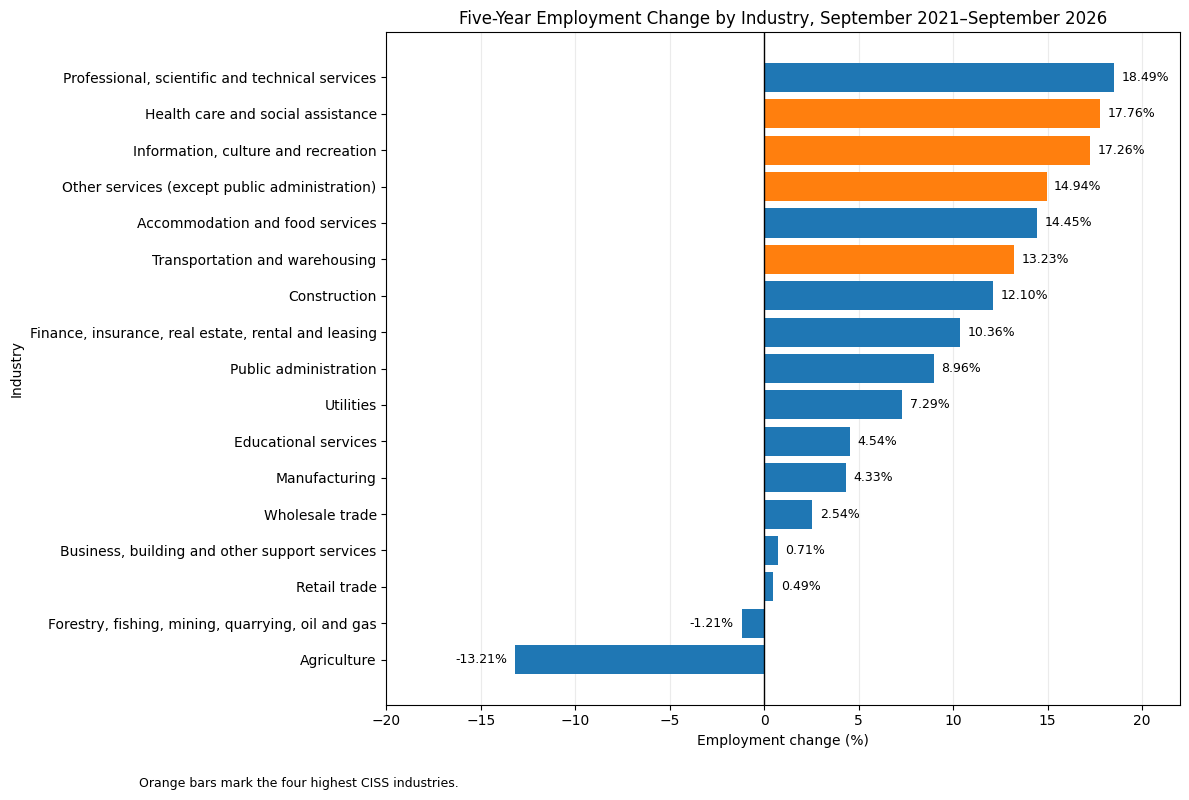

In [13]:
# Compare employment changes over the five-year period

chart = final_results.copy()
chart["label"] = chart["Industry"].str.replace(r"\s*\[.*?\]", "", regex=True)
chart = chart.sort_values("5-year employment change (%)")
values = chart["5-year employment change (%)"]

top4_labels = set(
    ciss_17.nlargest(4, "CISS")["industry"]
    .str.replace(r"\s*\[.*?\]", "", regex=True)
)
colors = ["#ff7f0e" if label in top4_labels else "#1f77b4" for label in chart["label"]]

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(chart["label"], values, color=colors)
ax.axvline(0, color="black", linewidth=1)

for bar, value in zip(bars, values):
    y_position = bar.get_y() + bar.get_height() / 2
    if value >= 0:
        x_position, alignment = value + 0.4, "left"
    else:
        x_position, alignment = value - 0.4, "right"
    ax.text(
        x_position, y_position, f"{value:.2f}%",
        va="center", ha=alignment, fontsize=9
    )

ax.set_title(f"Five-Year Employment Change by Industry, {five_year_start:%B %Y}–{latest_date:%B %Y}")
ax.set_xlabel("Employment change (%)")
ax.set_ylabel("Industry")
ax.set_xlim(-20, 22)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
fig.text(0.12, 0.01, "Orange bars mark the four highest CISS industries.", fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig(figures_folder / "five_year_employment_change.png", dpi=160, bbox_inches="tight")
plt.show()

## 14. Check the exported results

In [14]:
# Read the CSV again to check the file that will be shared

saved_results = pd.read_csv(output_file)
print("Number of industries:", len(saved_results))
print("Duplicate industry names:", saved_results["Industry"].duplicated().sum())
print("Missing values:", saved_results.isna().sum().sum())

print("\nTop four industries:")
display(saved_results[["Industry", "CISS score", "5-year employment change (%)"]].head(4))

assert len(saved_results) == 17
assert saved_results["Industry"].is_unique
assert saved_results.isna().sum().sum() == 0
assert np.allclose(saved_results["CISS score"].head(4), [98.53, 89.71, 89.71, 86.76], atol=0.01)

print("All final checks passed!")

Number of industries: 17
Duplicate industry names: 0
Missing values: 0

Top four industries:


,Industry,CISS score,5-year employment change (%)
0,"Information, culture and recreation [51, 71]",98.53,17.26
1,Transportation and warehousing [48-49],89.71,13.23
2,Health care and social assistance [62],89.71,17.76
3,Other services (except public administration) ...,86.76,14.94


All final checks passed!


## Interpretation notes

- CISS ranks industries relative to the 17 selected categories; it is not an official Statistics Canada measure.
- The latest growth estimate is also included in the 12-month consistency window, and successive year-over-year growth rates share underlying monthly changes.
- The growth-to-standard-error ratio is a rough screen, not a formal test. The scatter plot uses ±1 standard error, not 95% confidence intervals.
- The five-year comparison uses September 2021 and the latest month in the dataset. The starting month was part of the pandemic recovery period.